# Notebook: Train and Evaluate the Models

This notebook is the learning companion to `src/train_models.py`.

It explains the model design, data split, TF-IDF features, validation-based threshold tuning, and test evaluation. The final cell runs the actual Python training script so the notebook and production script use the same implementation.

## 1. Imports and project paths
The training script reads only the already prepared split CSVs. It does not clean or merge raw data again.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src" / "train_models.py").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed"
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)

print("Project root:", ROOT)
print("Prepared data exists:", DATA.exists())

Project root: /Users/kakulrajput/Documents/Smart_Community_ML
Prepared data exists: True


In [2]:
tox_train = pd.read_csv(DATA / "toxicity_train.csv")
tox_validation = pd.read_csv(DATA / "toxicity_validation.csv")
tox_test = pd.read_csv(DATA / "toxicity_test.csv")
spam_train = pd.read_csv(DATA / "spam_train.csv")
spam_validation = pd.read_csv(DATA / "spam_validation.csv")
spam_test = pd.read_csv(DATA / "spam_test.csv")

display(pd.DataFrame([
    {"task":"toxicity","split":"train","rows":len(tox_train)},
    {"task":"toxicity","split":"validation","rows":len(tox_validation)},
    {"task":"toxicity","split":"test","rows":len(tox_test)},
    {"task":"spam","split":"train","rows":len(spam_train)},
    {"task":"spam","split":"validation","rows":len(spam_validation)},
    {"task":"spam","split":"test","rows":len(spam_test)},
]))

,task,split,rows
0,toxicity,train,127499
1,toxicity,validation,15937
2,toxicity,test,15938
3,spam,train,4128
4,spam,validation,516
5,spam,test,516


In [3]:
import subprocess, sys
result = subprocess.run(
    [sys.executable, str(ROOT / "src" / "train_models.py")],
    cwd=ROOT,
    text=True,
    capture_output=True
)
print(result.stdout)
if result.stderr:
    print("---- messages / errors ----")
    print(result.stderr[-12000:])
if result.returncode != 0:
    raise RuntimeError(f"Training script failed with exit code {result.returncode}")

Training finished. Reports and thresholds are saved in artifacts/.
Toxicity macro F1: 0.6207 | micro F1: 0.7528
Spam accuracy: 0.9845 | spam F1: 0.9375 | threshold: 0.4799999999999998



## 2. Display test metrics directly in the notebook
These metrics are read from the report JSON files created by the training script. The JSON files are retained for reproducibility, but you do not need to open them manually.

In [4]:
tox_report_path = ARTIFACTS / "toxicity_test_report.json"
spam_report_path = ARTIFACTS / "sms_spam_test_report.json"
tox_result = json.loads(tox_report_path.read_text())
spam_result = json.loads(spam_report_path.read_text())

summary = pd.DataFrame([
    {"task":"Toxicity","macro_f1":tox_result["macro_f1"],"micro_f1":tox_result["micro_f1"],"accuracy":np.nan},
    {"task":"SMS spam","macro_f1":spam_result["classification_report"]["macro avg"]["f1-score"],
     "micro_f1":np.nan,"accuracy":spam_result["accuracy"]}
])
display(summary.round(4))
display(pd.DataFrame(tox_result["classification_report"]).T.round(4))
display(pd.DataFrame(spam_result["classification_report"]).T.round(4))

,task,macro_f1,micro_f1,accuracy
0,Toxicity,0.6207,0.7528,NaN
1,SMS spam,0.9643,NaN,0.9845


,precision,recall,f1-score,support
toxic,0.8371,0.7779,0.8064,1526.0
severe_toxic,0.3659,0.6475,0.4675,139.0
obscene,0.8023,0.8275,0.8147,829.0
threat,0.3913,0.4615,0.4235,39.0
insult,0.6721,0.7785,0.7214,790.0
identity_hate,0.4889,0.4925,0.4907,134.0
micro avg,0.7364,0.7700,0.7528,3457.0
macro avg,0.5929,0.6642,0.6207,3457.0
weighted avg,0.7536,0.7700,0.7588,3457.0
samples avg,0.0634,0.0708,0.0642,3457.0


,precision,recall,f1-score,support
ham,0.9912,0.9912,0.9912,452.0000
spam,0.9375,0.9375,0.9375,64.0000
accuracy,0.9845,0.9845,0.9845,0.9845
macro avg,0.9643,0.9643,0.9643,516.0000
weighted avg,0.9845,0.9845,0.9845,516.0000


## 3. Display tuned thresholds and confusion matrices inline
A confusion matrix helps separate false positives from false negatives. For moderation, both matter: false positives may wrongly flag harmless comments, while false negatives may miss harmful content.

,threshold
toxic,0.30
severe_toxic,0.12
obscene,0.18
threat,0.10
insult,0.18
identity_hate,0.16


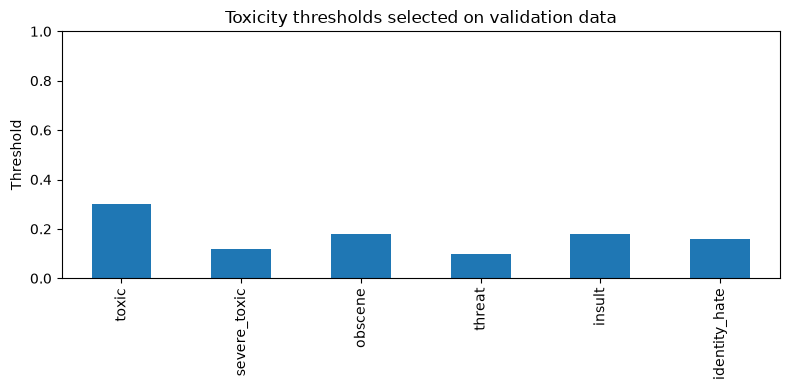

SMS spam threshold: 0.48


In [8]:
thresholds = pd.Series(tox_result["thresholds"], name="threshold")
display(thresholds.to_frame().round(3))
fig, ax = plt.subplots(figsize=(8,4))
thresholds.plot(kind="bar", ax=ax)
ax.set_title("Toxicity thresholds selected on validation data")
ax.set_ylabel("Threshold")
ax.set_ylim(0,1)
plt.tight_layout()
plt.show()
print("SMS spam threshold:", round(spam_result["threshold"], 3))

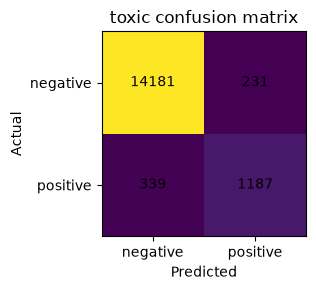

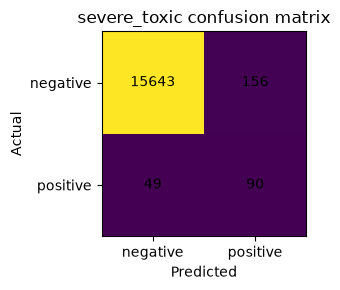

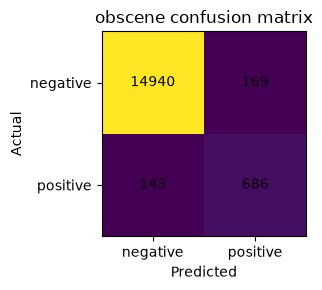

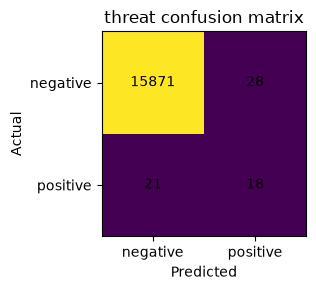

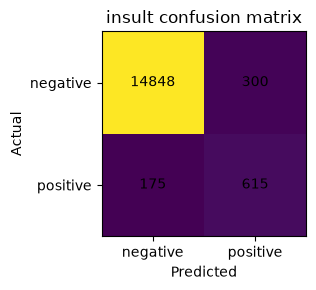

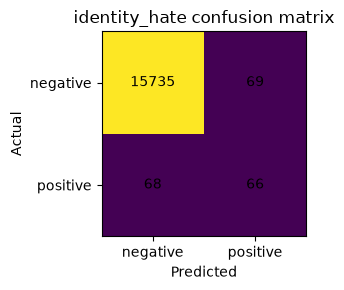

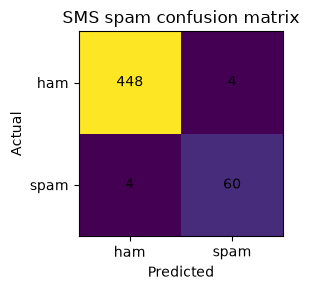

In [9]:
for label, matrix in tox_result["confusion_matrices"].items():
    fig, ax = plt.subplots(figsize=(4,3))
    ax.imshow(matrix, interpolation="nearest")
    ax.set_title(f"{label} confusion matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0,1], labels=["negative","positive"])
    ax.set_yticks([0,1], labels=["negative","positive"])
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, str(value), ha="center", va="center")
    plt.tight_layout()
    plt.show()

matrix = spam_result["confusion_matrix"]
fig, ax = plt.subplots(figsize=(4,3))
ax.imshow(matrix, interpolation="nearest")
ax.set_title("SMS spam confusion matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_xticks([0,1], labels=["ham","spam"])
ax.set_yticks([0,1], labels=["ham","spam"])
for (row, col), value in np.ndenumerate(matrix):
    ax.text(col, row, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()

## 7. Interpretation and responsible use

- Macro F1 weights labels/classes equally and is useful when labels are imbalanced.
- Precision measures how many predicted positives were correct.
- Recall measures how many actual positives were found.
- The SMS dataset is small and different from community comments. Its test score is not evidence that spam detection will work equally well on Smart Community posts.
- Validate on representative community data before production use.
- Treat toxicity scores as a signal for review, not an automatic reason to ban a user.